# Projekt - Sieć konwolucyjna do klasyfikacji zdjęć

Celem poniższego projektu jest binarna klasyfikacja zdjęć - czy zdjęcie jest wygenerowane przez Sztuczną Inteligencję, czy jest to zdjęcie prawdziwe

W zestawie danych znajduje się 79 950 zdjęć

Proporcje FAKE do REAL to 50/50 w obu zestawach - każde zdjęcie ma parę (odpowiednio Fake ma parę Real)





## 1. Wymagane biblioteki ---------------------------------------------------------------------















In [ ]:
import os  #
import numpy as np  #
import pandas as pd #
import torch  #
from PIL import Image as PILImage
from IPython.display import Image as IPImage
import torch.nn as nn
import torchvision
from torch.utils.data import Dataset, DataLoader, Subset

import matplotlib.pyplot as plt
import matplotlib.image as mpimg # do załadowania zdj z dysku
from torchvision import datasets, transforms
import torch.nn.functional as F
from sklearn.model_selection import train_test_split


from torch.optim.lr_scheduler import ReduceLROnPlateau
seed = 123  #ustalamy jeden seed na cały projekt

# 2. Ładowanie danych z dysku google ---------------------------------------------

Podłączanie dysku na którym znajdują sę dane

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


Wypakowanie danych z zip do pamięci Colab

In [ ]:
import zipfile
from pathlib import Path

zip_path = Path("/content/gdrive/MyDrive/Sieci_Neuronowe_Projekt_dane/data_2.zip")  #ścieżka musi pasować do nazwy folderu w jakim zapisane są dane - u mnie Sieci_Neuronowe_Projekt_dane/data_2.zip
extract_path = Path("/content/data")

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted files:")
!find /content/data -maxdepth 3 -type d

KeyboardInterrupt: 

In [ ]:
# Przenosimy zawartość ukrytego podfolderu poziom wyżej
!mv /content/data/data/* /content/data/ 2>/dev/null || true

# Dla pewności sprawdzamy, jak teraz wygląda struktura katalogów
print("Aktualna struktura folderów w /content/data:")
!find /content/data -maxdepth 2 -type d

Aktualna struktura folderów w /content/data:
/content/data
/content/data/train_data
/content/data/test_data_v2


Zdjęcia nie mają domyślnie podpisu target - informacje te znajdują się w plikach csv. Następne kroki pozwalają podpisać które zdjęcią są fałszywe a które prawdziwe.

Dodatkowo, zdjęcia w test nie mają podpisów wcale. Jest to spowodowane tym, iż dane te pochodzą z zawodów ML na Kaggle.
Z tego powodu wykorzystamy tylko folder train i z niego wydzielimy train/test/valid na nasze potrzeby.
W folderze znajduje się około 80 tys zdjęć, więc nie powinno być z tym problemu.

In [ ]:
train_csv_path = "/content/data/train.csv"
train_images_dir = "/content/data"

df = pd.read_csv(train_csv_path)

if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

print(df.head())
print(df.columns)
print(df["label"].value_counts())

                                         file_name  label
0  train_data/a6dcb93f596a43249135678dfcfc17ea.jpg      1
1  train_data/041be3153810433ab146bc97d5af505c.jpg      0
2  train_data/615df26ce9494e5db2f70e57ce7a3a4f.jpg      1
3  train_data/8542fe161d9147be8e835e50c0de39cd.jpg      0
4  train_data/5d81fa12bc3b4cea8c94a6700a477cf2.jpg      1
Index(['file_name', 'label'], dtype='object')
label
1    39975
0    39975
Name: count, dtype: int64


# 3. Przygotowanie danych ----------------------------------------------------------

Wydzielenie train/test/valid używając df z csv - nazwy plików i labele

In [ ]:
# Najpierw wydzielamy 50% train i 50% temp
train_df, temp_df = train_test_split(
    df,
    test_size=0.50,
    random_state=seed,
    stratify=df["label"]
)

# Potem 50% dzielimy na 20% valid i 30% test
valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.60,
    random_state=seed,
    stratify=temp_df["label"]
)

print("Train:", len(train_df))
print("Valid:", len(valid_df))
print("Test:", len(test_df))

print("\nRozkład klas train:")
print(train_df["label"].value_counts(normalize=True))

print("\nRozkład klas valid:")
print(valid_df["label"].value_counts(normalize=True))

print("\nRozkład klas test:")
print(test_df["label"].value_counts(normalize=True))

Train: 39975
Valid: 15990
Test: 23985

Rozkład klas train:
label
1    0.500013
0    0.499987
Name: proportion, dtype: float64

Rozkład klas valid:
label
1    0.5
0    0.5
Name: proportion, dtype: float64

Rozkład klas test:
label
0    0.500021
1    0.499979
Name: proportion, dtype: float64


Klasa do podpisywania obrazów mając csv z nazwami plików i labelami

In [ ]:
class RealFakeDataset(Dataset):
    def __init__(self, dataframe, root_dir, transform=None):
        """
        dataframe: DataFrame zawierający kolumny file_name oraz label
        root_dir: folder ze zdjęciami train_data
        transform: transformacje torchvision
        """
        self.df = dataframe.reset_index(drop=True)
        self.root_dir = root_dir
        self.transform = transform

        # Usuwanie zbędnej kolumny indeksów, jeśli istnieje
        if "Unnamed: 0" in self.df.columns:
            self.df = self.df.drop(columns=["Unnamed: 0"])

        # Kontrola wymaganych kolumn
        required_cols = ["file_name", "label"]
        for col in required_cols:
            if col not in self.df.columns:
                raise ValueError(f"Brakuje kolumny '{col}' w dataframe.")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.item()

        row = self.df.iloc[idx]

        image_path = os.path.join(self.root_dir, row["file_name"])
        label = int(row["label"])  # 1 - fake, 0 - real

        try:
            image = PILImage.open(image_path).convert("RGB")
        except FileNotFoundError:
            fallback_idx = 0 if idx != 0 else 1
            return self.__getitem__(fallback_idx)

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

Obrazy mają różne rozmiary oraz orientacje - wykonamy transformację aby miały jednolitą strukturę. Dane treningowe również losowo odbijamy oraz zniekształcamy.

In [ ]:
from torchvision import transforms

transform_train = transforms.Compose([
    transforms.Resize(178),
    transforms.RandomCrop([178, 178]),
    transforms.RandomHorizontalFlip(),
    transforms.Resize([64, 64]),
    transforms.ColorJitter(brightness=1.6),
    transforms.ToTensor(),          # ToTensor automatycznie normalizuje dane do przedziału [0,1]
])

transform_test = transforms.Compose([
    transforms.Resize(178),
    transforms.CenterCrop([178, 178]),
    transforms.Resize([64, 64]),
    transforms.ToTensor(),
])

In [ ]:
'''
Załadowanie datasetów postaci - zdjęcie po transformacji i label podany z csv
Transformacje na train opiewają również o losowe przycięcia, losowe odbicia oraz losowe zmiany jasności
'''

train_dataset = RealFakeDataset(
    dataframe=train_df,
    root_dir=train_images_dir,
    transform=transform_train
)

valid_dataset = RealFakeDataset(
    dataframe=valid_df,
    root_dir=train_images_dir,
    transform=transform_test
)

test_dataset = RealFakeDataset(
    dataframe=test_df,
    root_dir=train_images_dir,
    transform=transform_test
)

In [ ]:
'''
Budowa dataloaderów
'''

batch_size = 64

torch.manual_seed(seed)

train_dl = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    pin_memory=True,  # warto przy treningu na GPU - przyspiesza przenoszenie z RAM do GPU
    num_workers=2  # też pozwala przyspieszyć
)

valid_dl = DataLoader(
    valid_dataset,
    batch_size=batch_size,
    shuffle=False,
    pin_memory=True,
    num_workers=2
)

test_dl = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    pin_memory=True,
    num_workers=2
)

## Przykładowe zdjęcia ------------------------------

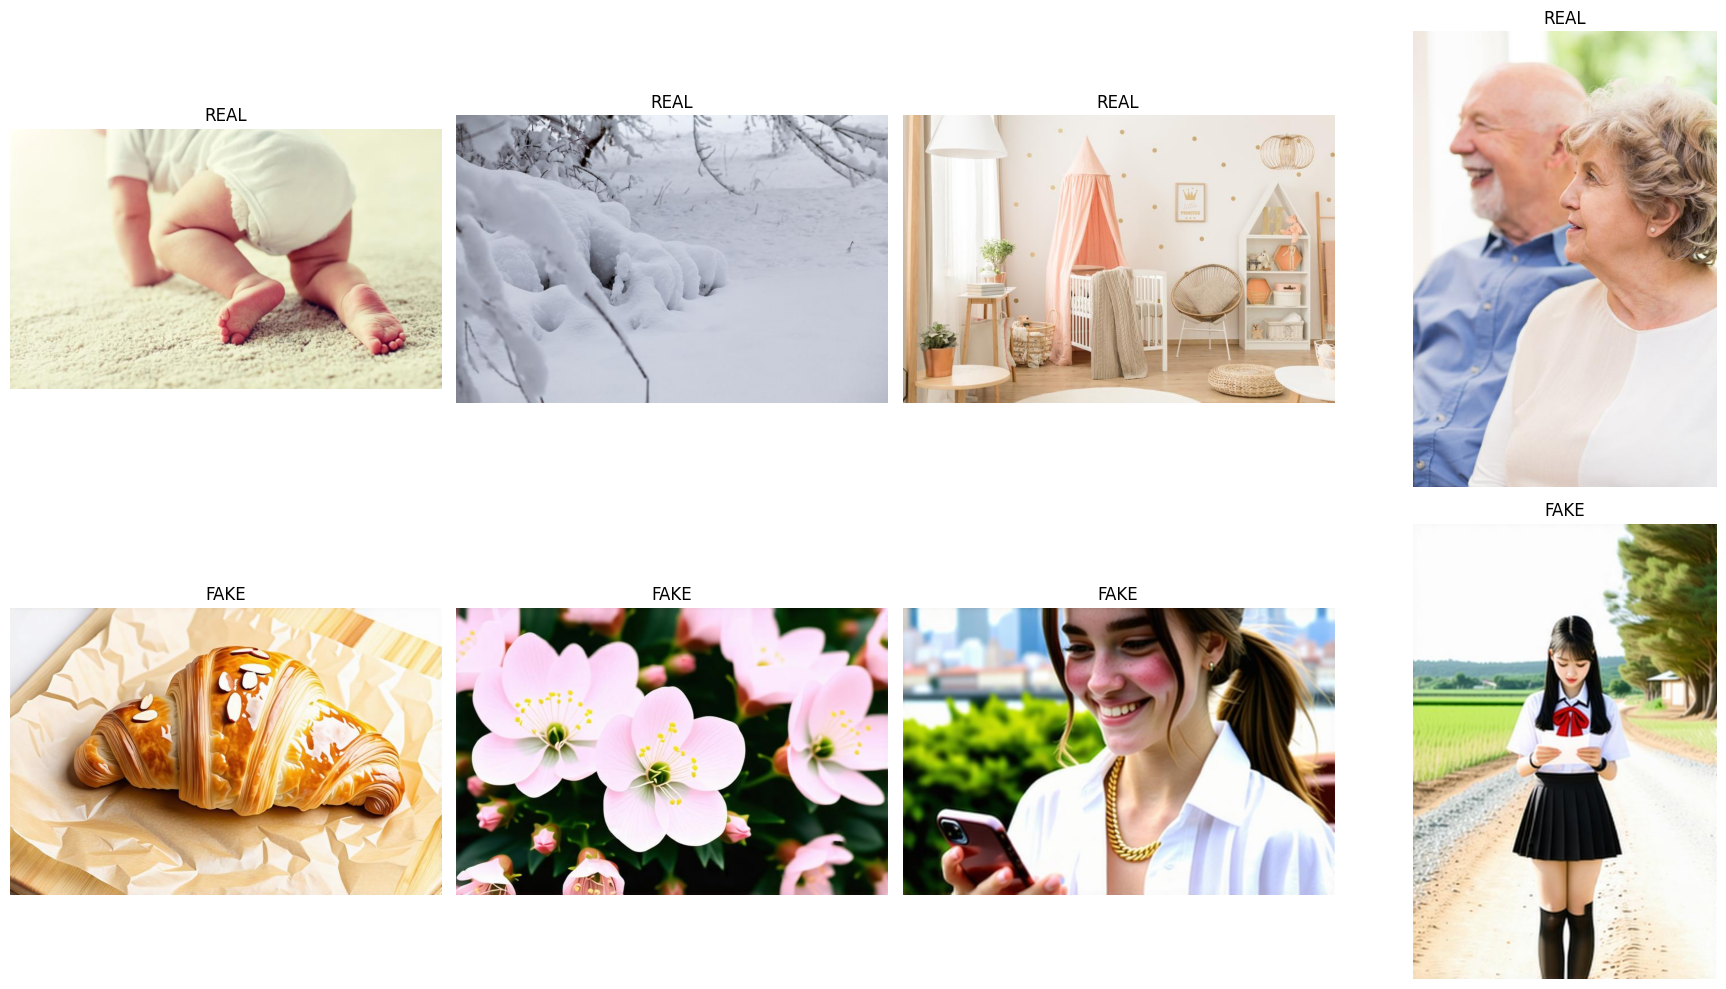

In [ ]:
def show_examples(df, images_dir, n_per_class=4):
    real_examples = df[df["label"] == 0].sample(n_per_class, random_state=42)
    fake_examples = df[df["label"] == 1].sample(n_per_class, random_state=42)

    examples = pd.concat([real_examples, fake_examples]).reset_index(drop=True)

    plt.figure(figsize=(18, 10))

    for i, row in examples.iterrows():
        image_path = os.path.join(images_dir, row["file_name"])
        image = PILImage.open(image_path).convert("RGB")

        label = int(row["label"])
        label_name = "REAL" if label == 0 else "FAKE"

        plt.subplot(2, 4, i + 1)
        plt.imshow(image)
        plt.title(label_name)
        plt.axis("off")

    plt.tight_layout()



    plt.show()

show_examples(train_df, '/content/data', n_per_class=4)

# 4. Przygotowanie funkcji do trenowania modeli ------------------------------

W tej części zajmiemy się budową funkcji potrzebnych do trenowania modeli.

In [ ]:
def plot(train_loss, valid_loss, train_acc, valid_acc):
    '''
    Stwórz wykres postępu uczenia względem loss i acc na zbiorze treningowym oraz testowym

    '''


    os.environ['KMP_DUPLICATE_LIB_OK']='True'



    x_arr = np.arange(len(train_loss)) + 1

    fig = plt.figure(figsize=(12, 4))
    ax = fig.add_subplot(1, 2, 1)
    ax.plot(x_arr, train_loss, '-o', label='Train loss')
    ax.plot(x_arr, valid_loss, '--<', label='Validation loss')
    ax.set_xlabel('Epoch', size=15)
    ax.set_ylabel('Loss', size=15)
    ax.legend(fontsize=15)
    ax = fig.add_subplot(1, 2, 2)
    ax.plot(x_arr, train_acc, '-o', label='Train acc.')
    ax.plot(x_arr, valid_acc, '--<', label='Validation acc.')
    ax.legend(fontsize=15)
    ax.set_xlabel('Epoch', size=15)
    ax.set_ylabel('Accuracy', size=15)

In [ ]:
def train(
    model,
    num_epochs,
    train_dl,
    valid_dl,
    model_name,
    platoe=False,
    SAVE=False,
    start_epoch=0,
    loss_hist_train=None,
    loss_hist_valid=None,
    accuracy_hist_train=None,
    accuracy_hist_valid=None,
    current_lr_hist=None
):
    '''
    Funkcja do trenowania modelu
    model: model CNN
    model_name: pozwala na podanie nazwy do zapisu informacji o modelu - pkl (struktura modelu), checkpoint (stan uczenia modelu), plot (postęp uczenia na wykresach)
    platoe: TRUE jeżeli chcemy używać ReduceOnPlatoe jako zmiana learning rate gdy uczenie zwalnia za bardzo, False jeżeli używamy learning rate zmiennego w czasie (np skokowy itp)

    DLA UCZENIA Z CHECKPOINT - DOUCZANIE:
    start_epoch: jeżeli chcemy uczyć z checkpointa to musimy podać od jakiej epoki ponawiamy uczenie
    loss_hist_train,loss_hist_valid ... :  zeby móc podać parametry jakie były w checkpoint

    '''


    if loss_hist_train is None:
        loss_hist_train = []
    if loss_hist_valid is None:
        loss_hist_valid = []
    if accuracy_hist_train is None:
        accuracy_hist_train = []
    if accuracy_hist_valid is None:
        accuracy_hist_valid = []
    if current_lr_hist is None:
        current_lr_hist = []

    SAVE_DIR = "/content/gdrive/MyDrive/Sieci_Neuronowe_Projekt_dane/model_checkpoints"   #gdrive nie drive - gdrive to google drive - tutaj zapisują się informacje o uczonych modelach
    os.makedirs(SAVE_DIR, exist_ok=True)



    for epoch in range(start_epoch, num_epochs):

        model.train()

        train_loss = 0
        train_acc = 0

        for x_batch, y_batch in train_dl:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            pred = model(x_batch)
            loss = loss_fn(pred, y_batch)

            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

            train_loss += loss.item() * y_batch.size(0)
            is_correct = (torch.argmax(pred, dim=1) == y_batch).float()
            train_acc += is_correct.sum().cpu()

        train_loss /= len(train_dl.dataset)
        train_acc /= len(train_dl.dataset)

        model.eval()

        valid_loss = 0
        valid_acc = 0

        with torch.no_grad():
            for x_batch, y_batch in valid_dl:
                x_batch = x_batch.to(device)
                y_batch = y_batch.to(device)

                pred = model(x_batch)
                loss = loss_fn(pred, y_batch)

                valid_loss += loss.item() * y_batch.size(0)
                is_correct = (torch.argmax(pred, dim=1) == y_batch).float()
                valid_acc += is_correct.sum().cpu()

        valid_loss /= len(valid_dl.dataset)
        valid_acc /= len(valid_dl.dataset)

        loss_hist_train.append(train_loss)
        loss_hist_valid.append(valid_loss)
        accuracy_hist_train.append(train_acc)
        accuracy_hist_valid.append(valid_acc)

        if platoe:      #Zmiana LR patrząc na to czy celność na valid nie zwalnia za bardzo
            scheduler.step(valid_acc)
        else:
            scheduler.step()

        current_lr = scheduler.get_last_lr()[0]
        current_lr_hist.append(current_lr)

        print(
            f"Epoch {epoch + 1} accuracy: {train_acc:.4f} "
            f"val_accuracy: {valid_acc:.4f} lr: {current_lr:.6f}"
        )

        if SAVE:       # zapis checkpointa i pkl co 5 epok
            if (epoch + 1) % 5 == 0:
                checkpoint_path = f"{SAVE_DIR}/checkpoint_{model_name}_training.pth"   #nadpisywanie bo chcemy tylko najnowszy checkpoint

                torch.save({
                    "epoch": epoch + 1,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "scheduler_state_dict": scheduler.state_dict(),
                    "train_loss": loss_hist_train,
                    "valid_loss": loss_hist_valid,
                    "train_acc": accuracy_hist_train,
                    "valid_acc": accuracy_hist_valid,
                    "lr_hist": current_lr_hist,
                }, checkpoint_path)
                PATH = f"{SAVE_DIR}/model_files_{model_name}_epoch_number_{epoch+1}.pkl"    #zapisywanie struktury modelu w .pkl co 5 epok - jeżeli widzimy że po 30 epoce już jest przeuczony to bierzemy model np dla epoki 25 etc
                torch.save(model, PATH)

                print(f"Checkpoint saved: {checkpoint_path}")

    plot(history_to_float(loss_hist_train), history_to_float(loss_hist_valid), history_to_float(accuracy_hist_train), history_to_float(accuracy_hist_valid))
    plot_path =  os.path.join(f'{SAVE_DIR}', f'{model_name}_training.png')        #zapis plota do danych
    plt.savefig(plot_path, dpi=300, bbox_inches="tight")
    plt.show()
    return loss_hist_train, loss_hist_valid, accuracy_hist_train, accuracy_hist_valid

In [ ]:
def reset_weights(m):
    '''
    resetuje wagi modelu jeżeli chcemy testować uczenie ponownie
    '''
    if hasattr(m, 'reset_parameters'):
        m.reset_parameters()

In [ ]:
def xavier_init(module):
    '''
    Ustawia wagi według inicjalizacji Xaviera Glorota
    '''
    if isinstance(module, nn.Conv2d):
        nn.init.xavier_uniform_(module.weight)
        if module.bias is not None:
            nn.init.zeros_(module.bias)
    elif isinstance(module, nn.Linear):
        nn.init.xavier_uniform_(module.weight)
        if module.bias is not None:
            nn.init.zeros_(module.bias)

In [ ]:
'''
Do testowania czy uczy się sieć - podzbiór
Dobre jak sie dużo uczy a chcemy przetestować coś - tym bardziej jak akurat nie mamy dostępnych GPU
'''


from torch.utils.data import Subset

subset_size =2000
small_train_dataset = Subset(train_dataset, list(range(  round(0.7*subset_size)  )))
small_valid_dataset = Subset(valid_dataset, list(range(  subset_size - round(0.7*subset_size))))


small_train_dl = DataLoader(
    small_train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=2,
    )

small_valid_dl = DataLoader(
    small_valid_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2,
   )

In [ ]:
def history_to_float(history):
    '''
    Przy uczeniu na GPU gdy chcemy odpalić plot to musimy przekonwertować tensory na czyste float
    '''
    fixed = []
    for x in history:
        if torch.is_tensor(x):
            fixed.append(x.detach().cpu().item())
        else:
            fixed.append(float(x))
    return fixed

In [ ]:
SAVE_DIR = "/content/gdrive/MyDrive/Sieci_Neuronowe_Projekt_dane/model_checkpoints"   #gdrive nie drive - gdrive to google drive - tutaj zapisują się informacje o uczonych modelach
os.makedirs(SAVE_DIR, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
def train_from_checkpoint(model_name, choosen_model_epoch, num_epochs):
  '''
  Funkcja do douczania modelu mając jego plik pkl oraz zapis checkpointa
  model_name: jak nazwaliśmy nasz model
  choosen_model_epoch: dla której epoki mamy model i checkpoint - jeżeli skończyliśmy uczenie na model_epoch_15 i dla 15 epoki mamy checkpoint to ustalamy na 15
  num_epochs: ile epok dodatkowo douczać - zalecane 15
  '''

  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
  try:
    model = torch.load(f"/content/gdrive/MyDrive/Sieci_Neuronowe_Projekt_dane/model_checkpoints/model_files_{model_name}_epoch_number_{choosen_model_epoch}.pkl",  map_location=device, weights_only=False)
    model = model.to(device)




    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)  #dokładne parametry nie są ważne bo i tak będą wczytane z checkpointa
    scheduler = ReduceLROnPlateau(optimizer,"max", patience=2, threshold  = 0.01,  factor=0.7,min_lr = 0.00001)




    checkpoint_path  = f"{SAVE_DIR}/checkpoint_{model_name}_training.pth"
    checkpoint = torch.load(checkpoint_path, map_location=device)

    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])




    start_epoch = checkpoint["epoch"]
    loss_hist_train = checkpoint["train_loss"]
    loss_hist_valid = checkpoint["valid_loss"]
    accuracy_hist_train = checkpoint["train_acc"]
    accuracy_hist_valid = checkpoint["valid_acc"]
    current_lr_hist = checkpoint["lr_hist"]
    good_to_train=True
  except:
    print('Brak wymaganych plików pkl i checkpoint, lub niepoprawna nazwa folderu na dysku')
    good_to_train=False
    return 0

  if good_to_train:

    model_hist_after_checkpoint = train(
        model,
        num_epochs=start_epoch+num_epochs,
        train_dl= train_dl,
        valid_dl= valid_dl,
        model_name= model_name,
        platoe=True,
        SAVE=True,
        start_epoch=start_epoch,
        loss_hist_train=loss_hist_train,
        loss_hist_valid=loss_hist_valid,
        accuracy_hist_train=accuracy_hist_train,
        accuracy_hist_valid=accuracy_hist_valid,
        current_lr_hist=current_lr_hist
        )
    return model_hist_after_checkpoint






# 5. Budowa modeli

## Naukę modeli dzielimy na etapy:

 - Uczenie - początkowe 15 epok nauk modelu po którym (o ile nie zostanie rozłączone środowisko) otrzymamy 3 pliki plk, 1 plik checkpoint i 1 plot. Wykorzystując plot ocenimy, czy model wymaga dalszej nauki, czy lr jest zbyt mały (powolny wzrost) czy zbyt duży (skaczące wartości valid).

 - Douczanie - wczytujemy informacje o modelu z pkl i checkpointa i wznawiamy uczenie w epokach 15-30, po czym sprawdzamy plot analogicznie do etapu 'Uczenie'. Powtarzamy dopóki nie widzimy że model nie wykonuje postępów.

 - Gotowy model - Wczytujemy końcowy model który nas interesuje z pliku .pkl i wykorzystujemy do testu

 Uwaga - 15 epok na każdym etapie to zalecana liczba, gdyż dla większej ilości colab często odłącza środowisko - zapisywanie checkpointów pozwala uniknąć problemów z tym związanych, ale nadal szkoda marnować czasu i zasobów na epoki które zostaną stracone.

## Model 1 małe CNN

2 małe warstwy CONV
optim - adam lr = 0.0005
zmienny rate - reduce on platoe

In [ ]:
model_1 = nn.Sequential(
    nn.Conv2d(3, 16, kernel_size=3, padding=2),  nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(16, 32, kernel_size=3, padding=2), nn.ReLU(), nn.MaxPool2d(2)
)

model_1.add_module('flatten', nn.Flatten())

model_1.add_module('fc1', nn.Linear(9248, 4200))
model_1.add_module('relu3', nn.ReLU())
model_1.add_module('dropout', nn.Dropout(p=0.5))

model_1.add_module('fc3', nn.Linear(4200, 2))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_1 = model_1.to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_1.parameters(), lr=0.0005)
model_1.apply(xavier_init)

torch.manual_seed(seed)

scheduler = ReduceLROnPlateau(optimizer,"max", patience=2, threshold  = 0.01,  factor=0.5,min_lr = 0.00001)

In [ ]:
#reset_weights(model_1)

In [ ]:
#model_1_hist = train(model_1, num_epochs=15, train_dl = train_dl, valid_dl = valid_dl, model_name='Model_1', platoe = True, SAVE = True)

Douczanie modelu 1

In [ ]:
#model_1_hist_after_checkpoint = train_from_checkpoint('Model_1', 15, 15)

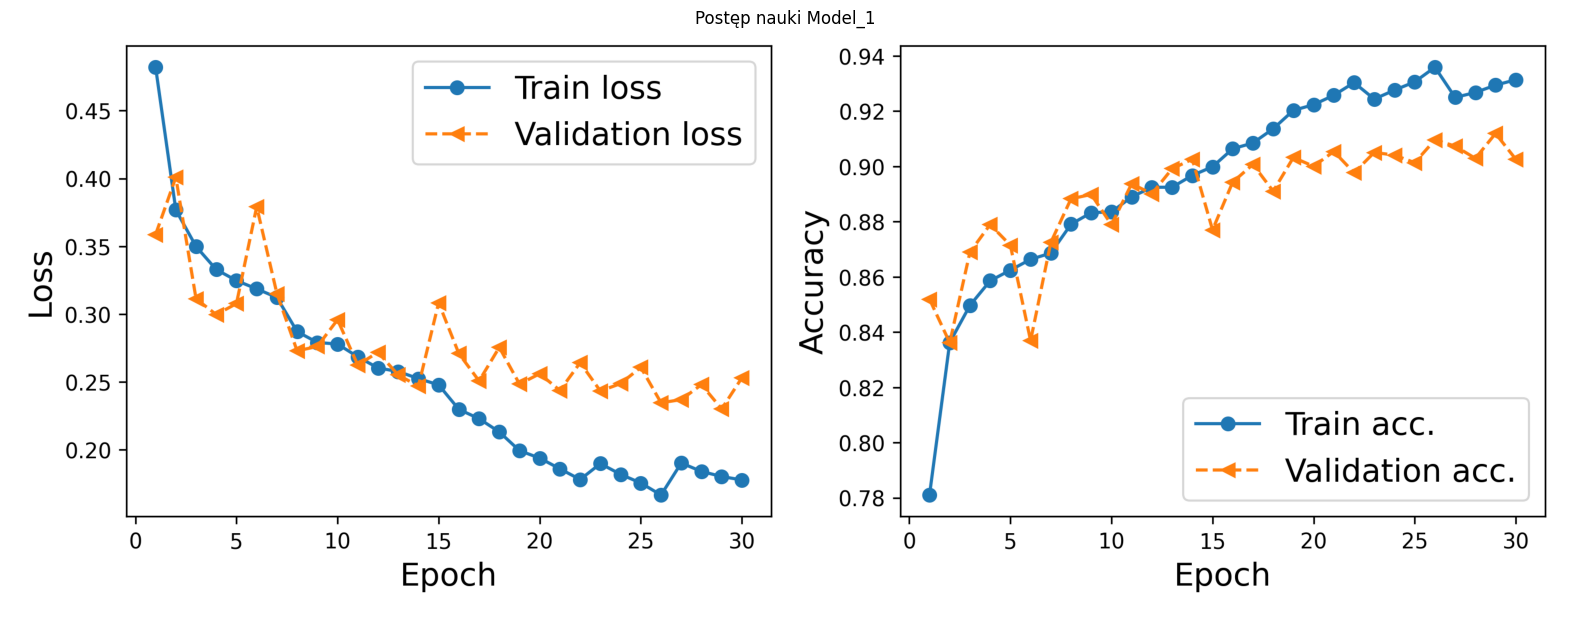

In [ ]:
try:
  img = mpimg.imread(f'{SAVE_DIR}/Model_1_training.png')
  plt.figure(figsize=(20, 10))
  plt.imshow(img)

  plt.title("Postęp nauki Model_1")
  plt.axis("off")
  plt.show()
except:
  print('Brak pliku ze zdjęciem')

## Przykładowe Wznawianie z checkpointa

# Model 2 większy

In [ ]:
model_2 = nn.Sequential(
    nn.Conv2d(3, 30, kernel_size=3, padding=2),  nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(30, 60, kernel_size=3, padding=2), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(60, 120, kernel_size=3, padding=2), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(120, 140, kernel_size=3, padding=2), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(140, 280, kernel_size=3, padding=2), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(280, 560, kernel_size=3, padding=2), nn.ReLU(), nn.MaxPool2d(2)
)

model_2.add_module('flatten', nn.Flatten())
model_2.add_module('fc1', nn.Linear(2240, 1100))
model_2.add_module('relu3', nn.ReLU())
model_2.add_module('dropout', nn.Dropout(p=0.5))

model_2.add_module('fc3', nn.Linear(1100, 2))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_2 = model_2.to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_2.parameters(), lr=0.0002)
model_2.apply(xavier_init)
torch.manual_seed(seed)

scheduler = ReduceLROnPlateau(optimizer,"max", patience=3, threshold  = 0.003,  factor=0.5,min_lr = 0.00001)


In [ ]:
#model_2_hist = train(model_2, num_epochs=15, train_dl = train_dl, valid_dl = valid_dl, model_name='Model_2', platoe = True, SAVE = True)

Douczanie modelu 2

In [ ]:
#model_2_hist_after_checkpoint =  train_from_checkpoint('Model_2', 15, 15)

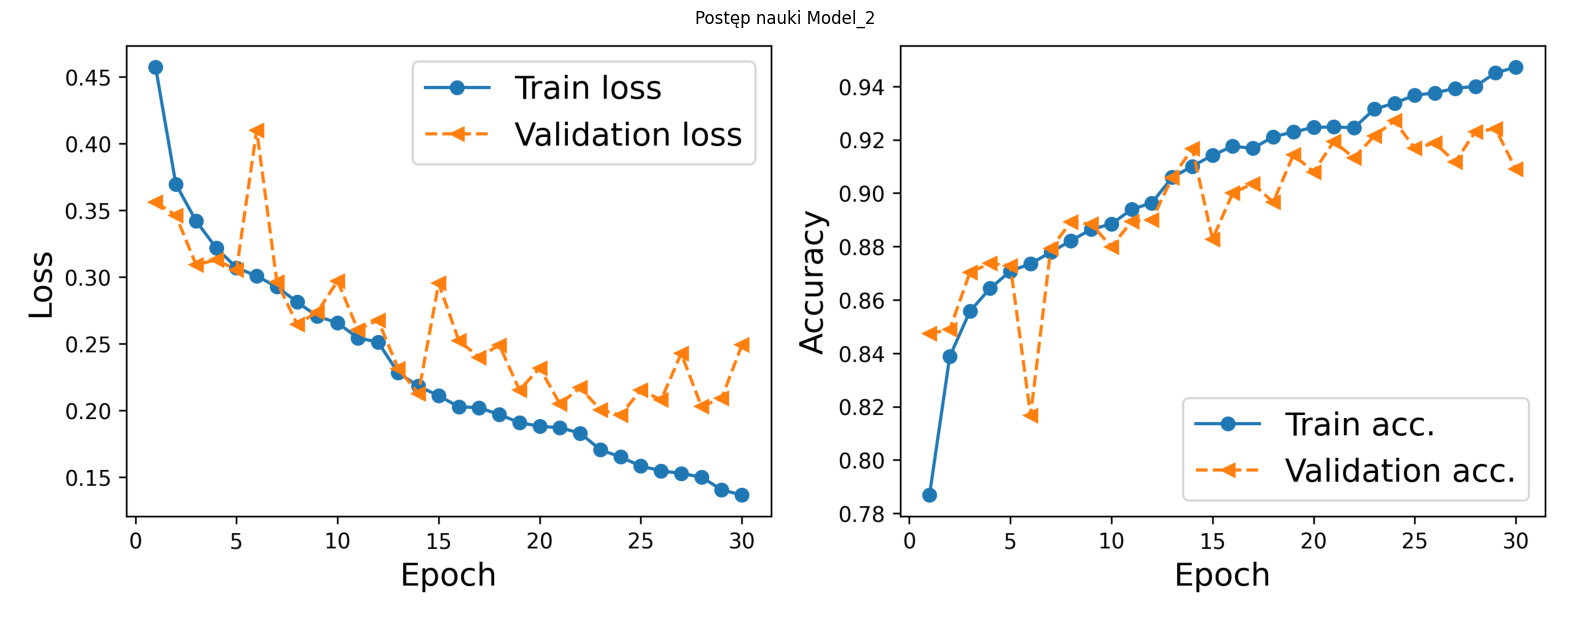

In [ ]:
try:
  img = mpimg.imread(f'{SAVE_DIR}/Model_2_training.png')
  plt.figure(figsize=(20, 10))
  plt.imshow(img)

  plt.title("Postęp nauki Model_2")
  plt.axis("off")
  plt.show()
except:
  print('Brak pliku ze zdjęciem')

In [ ]:
model_3 = nn.Sequential(
    nn.Conv2d(3, 20, kernel_size = 3, padding = 1), nn.LeakyReLU(), nn.MaxPool2d(2),
    nn.Conv2d(20, 40, kernel_size = 3, padding = 1), nn.LeakyReLU(), nn.MaxPool2d(2),
    nn.Conv2d(40, 80, kernel_size = 3, padding = 1), nn.LeakyReLU(), nn.MaxPool2d(2),
    nn.Conv2d(80, 140, kernel_size = 3, padding = 1), nn.LeakyReLU(), nn.MaxPool2d(2)
)

model_3.add_module('flatten', nn.Flatten())
model_3.add_module('fc1', nn.Linear(2240, 1100))
model_3.add_module('leaky_relu', nn.LeakyReLU())
model_3.add_module('dropout', nn.Dropout(p = 0.3))

model_3.add_module('fc2', nn.Linear(1100, 550))
model_3.add_module('leaky_relu', nn.LeakyReLU())
model_3.add_module('dropout', nn.Dropout(p = 0.3))

model_3.add_module('fc3', nn.Linear(550, 2))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_3 = model_3.to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_3.parameters(), lr = 0.001)
model_3.apply(xavier_init)
torch.manual_seed(seed)

scheduler = ReduceLROnPlateau(optimizer, 'max', patience = 2, threshold = 0.005, factor = 0.2, min_lr = 0.00001)

Epoch 1 accuracy: 0.7906 val_accuracy: 0.8027 lr: 0.001000
Epoch 2 accuracy: 0.8451 val_accuracy: 0.8679 lr: 0.001000
Epoch 3 accuracy: 0.8574 val_accuracy: 0.8804 lr: 0.001000
Epoch 4 accuracy: 0.8630 val_accuracy: 0.8627 lr: 0.001000
Epoch 5 accuracy: 0.8714 val_accuracy: 0.8588 lr: 0.001000
Checkpoint saved: /content/gdrive/MyDrive/Sieci_Neuronowe_Projekt_dane/model_checkpoints/checkpoint_Model_3_training.pth
Epoch 6 accuracy: 0.8742 val_accuracy: 0.8829 lr: 0.000200
Epoch 7 accuracy: 0.8899 val_accuracy: 0.8802 lr: 0.000200
Epoch 8 accuracy: 0.8949 val_accuracy: 0.8733 lr: 0.000200
Epoch 9 accuracy: 0.8983 val_accuracy: 0.8928 lr: 0.000200
Epoch 10 accuracy: 0.8972 val_accuracy: 0.8611 lr: 0.000200
Checkpoint saved: /content/gdrive/MyDrive/Sieci_Neuronowe_Projekt_dane/model_checkpoints/checkpoint_Model_3_training.pth
Epoch 11 accuracy: 0.8991 val_accuracy: 0.8774 lr: 0.000200
Epoch 12 accuracy: 0.9017 val_accuracy: 0.8894 lr: 0.000040
Epoch 13 accuracy: 0.9076 val_accuracy: 0.8932 

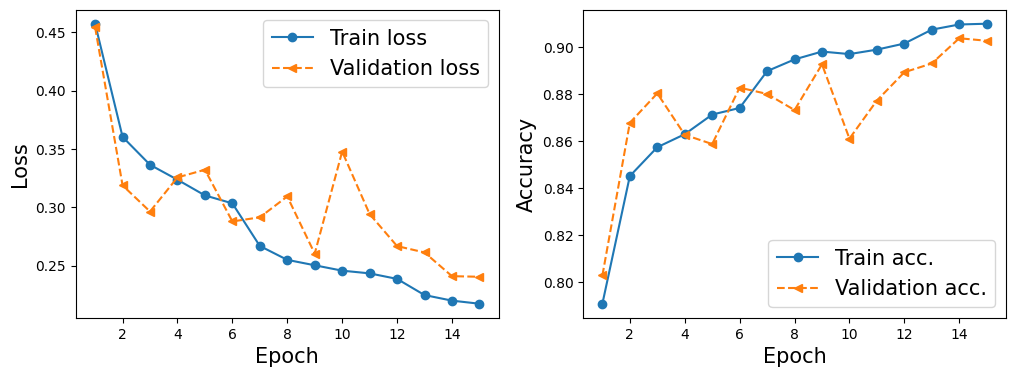

In [ ]:
#model_3_hist = train(model_3, num_epochs = 15, train_dl = train_dl, valid_dl = valid_dl, model_name = 'Model_3', platoe = True, SAVE = True)

Epoch 16 accuracy: 0.9129 val_accuracy: 0.9029 lr: 0.000040
Epoch 17 accuracy: 0.9114 val_accuracy: 0.9029 lr: 0.000010
Epoch 18 accuracy: 0.9087 val_accuracy: 0.9029 lr: 0.000010
Epoch 19 accuracy: 0.9115 val_accuracy: 0.9029 lr: 0.000010
Epoch 20 accuracy: 0.9102 val_accuracy: 0.9029 lr: 0.000010
Checkpoint saved: /content/gdrive/MyDrive/Sieci_Neuronowe_Projekt_dane/model_checkpoints/checkpoint_Model_3_training.pth
Epoch 21 accuracy: 0.9116 val_accuracy: 0.9029 lr: 0.000010
Epoch 22 accuracy: 0.9115 val_accuracy: 0.9029 lr: 0.000010
Epoch 23 accuracy: 0.9119 val_accuracy: 0.9029 lr: 0.000010
Epoch 24 accuracy: 0.9111 val_accuracy: 0.9029 lr: 0.000010
Epoch 25 accuracy: 0.9109 val_accuracy: 0.9029 lr: 0.000010
Checkpoint saved: /content/gdrive/MyDrive/Sieci_Neuronowe_Projekt_dane/model_checkpoints/checkpoint_Model_3_training.pth
Epoch 26 accuracy: 0.9114 val_accuracy: 0.9029 lr: 0.000010
Epoch 27 accuracy: 0.9110 val_accuracy: 0.9029 lr: 0.000010
Epoch 28 accuracy: 0.9110 val_accuracy

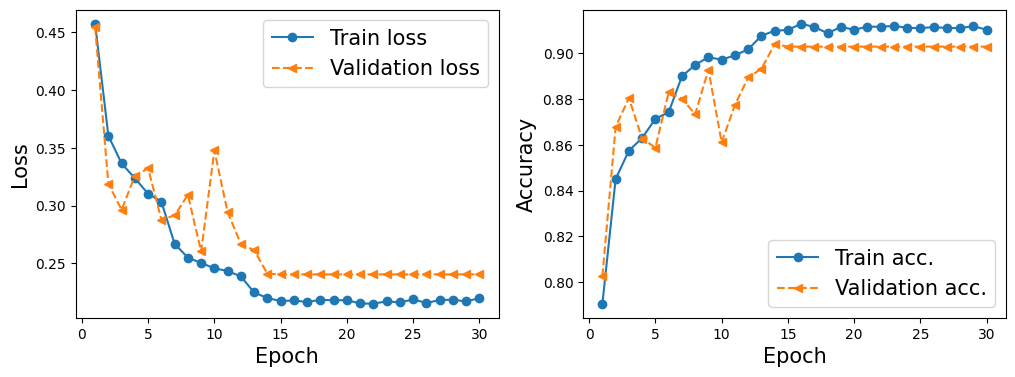

In [ ]:
#model_3_hist_after_checkpoint =  train_from_checkpoint('Model_3', 15, 15)

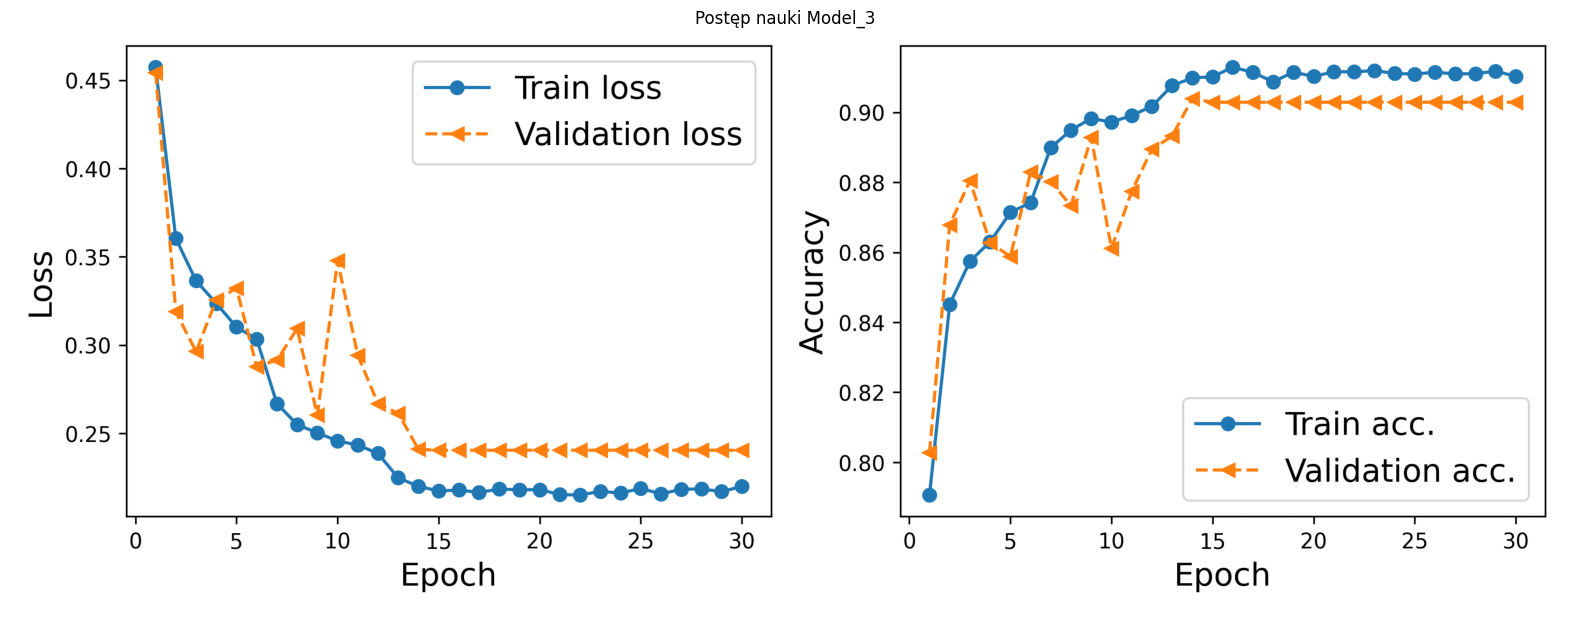

In [ ]:
try:
  img = mpimg.imread(f'{SAVE_DIR}/Model_3_training.png')
  plt.figure(figsize=(20, 10))
  plt.imshow(img)

  plt.title("Postęp nauki Model_3")
  plt.axis("off")
  plt.show()
except:
  print('Brak pliku ze zdjęciem')

In [ ]:
def accuracy_score(y_true, y_pred):
    correct = 0
    total = len(y_true)

    for true, pred in zip(y_true, y_pred):
        if true == pred:
            correct += 1

    return correct / total

In [ ]:
def evaluate_on_valid(model, valid_dl):
  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
  model = model.to(device)
  model.eval()

  lab_true = []
  lab_pred = []

  with torch.no_grad():
    for img_batch, lab_batch in valid_dl:
      img_batch = img_batch.to(device)
      lab_batch = lab_batch.to(device)

      outputs = model(img_batch)
      _, preds = torch.max(outputs, 1)

      lab_true.extend(lab_batch.cpu().numpy())
      lab_pred.extend(preds.cpu().numpy())

  acc = accuracy_score(lab_true, lab_pred)


  return(acc)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_1_15 = torch.load(
    "/content/gdrive/MyDrive/Sieci_Neuronowe_Projekt_dane/model_checkpoints1,2/model_files_Model_1_epoch_number_15.pkl",
    map_location=device,
    weights_only=False
)

model_2_15 = torch.load(
    "/content/gdrive/MyDrive/Sieci_Neuronowe_Projekt_dane/model_checkpoints1,2/model_files_Model_2_epoch_number_15.pkl",
    map_location=device,
    weights_only=False
)

model_3_15 = torch.load(
    "/content/gdrive/MyDrive/Sieci_Neuronowe_Projekt_dane/model_checkpoints3/model_files_Model_3_epoch_number_15.pkl",
    map_location=device,
    weights_only=False
)

In [ ]:
eval1 = evaluate_on_valid(model_1_15, valid_dl)
eval2 = evaluate_on_valid(model_2_15, valid_dl)
eval3 = evaluate_on_valid(model_3_15, valid_dl)

In [ ]:
wyniki = {
    'model_1': eval1,
    'model_2': eval2,
    'model_3': eval3,
}

print('wyniki na zbiorze validcyjnym:')
for k, v in wyniki.items():
  print(f'| {k}: {v} |')

wyniki na zbiorze validcyjnym:
| model_1: 0.8769856160100062 |
| model_2: 0.8827392120075047 |
| model_3: 0.9028767979987492 |


widzimy że najlepszym spośród modeli na zbiorze walidacyjnym jest model_3. sprawdzimy jego jakość na zbiorze treningowym.

In [ ]:
def evaluate_on_test(model, test_dl):
  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

  model = model.to(device)
  model.eval()

  lab_true = []
  lab_pred = []

  with torch.no_grad():
      for img_batch, lab_batch in test_dl:
        img_batch = img_batch.to(device)
        lab_batch = lab_batch.to(device)

        outputs = model(img_batch)
        _, preds = torch.max(outputs, 1)

        lab_true.extend(lab_batch.cpu().numpy())
        lab_pred.extend(preds.cpu().numpy())

  acc = accuracy_score(lab_true, lab_pred)


  return(acc)

In [ ]:
evaluate_on_test(model_3_15, test_dl)

0.903272878882635